# Model Development

## A. Load clean dataset and separate target from predictors

In [21]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate,
    RandomizedSearchCV
)

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

from sklearn.ensemble import RandomForestClassifier

from imblearn.over_sampling import SMOTENC
from imblearn.pipeline import Pipeline as ImbPipeline

from xgboost import XGBClassifier

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    RocCurveDisplay,
    precision_score,
    recall_score,
    f1_score,
    accuracy_score
)

import warnings
warnings.filterwarnings("ignore")

RANDOM_STATE = 42

# Load cleaned dataset
df = pd.read_csv(
    "../data/processed/cleaned_telco_churn.csv"
)

print("Dataset shape:", df.shape)

df.head()

Dataset shape: (7043, 20)


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,0
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1


In [22]:
x = df.drop(columns=["Churn"])

df["SeniorCitizen"] = df["SeniorCitizen"].astype(object)

y = df["Churn"].astype(int)

print("Features shape:", x.shape)
print("Target shape:", y.shape)

Features shape: (7043, 19)
Target shape: (7043,)


In [23]:
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [30]:
# Identify feature types



numerical_features = x_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = x_train.select_dtypes(
    include=["object"]
).columns.tolist()

print("Numerical features:", numerical_features)
print("Number of numerical features:", len(numerical_features))

print("\nCategorical features:", categorical_features)
print("Number of categorical features:", len(categorical_features))

Numerical features: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
Number of numerical features: 4

Categorical features: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']
Number of categorical features: 15


In [25]:
print("Training features:", x_train.shape)
print("Testing features:", x_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Training features: (5634, 19)
Testing features: (1409, 19)

Training target distribution:
Churn
0    4139
1    1495
Name: count, dtype: int64

Testing target distribution:
Churn
0    1035
1     374
Name: count, dtype: int64


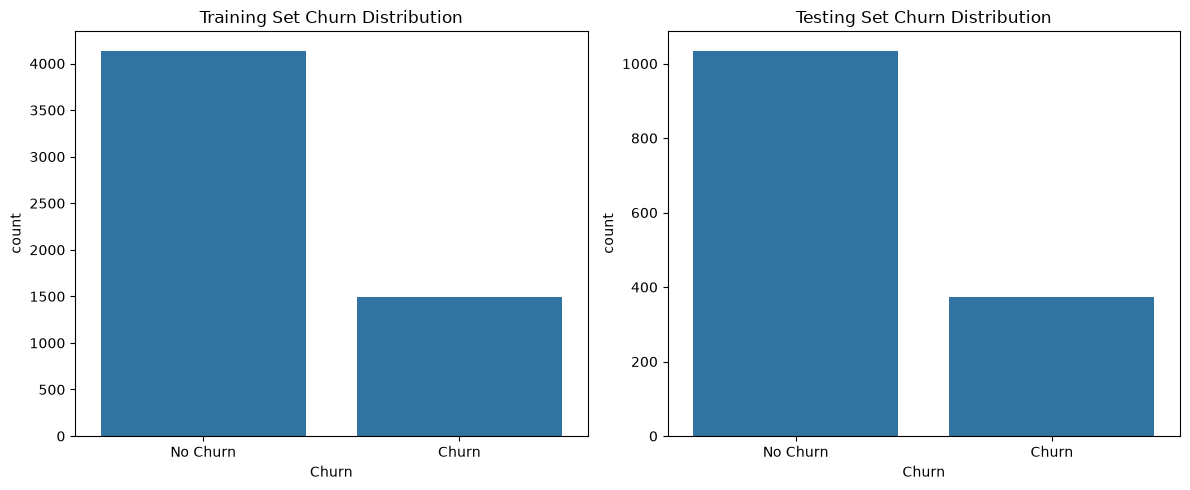

In [26]:
# Visualize the distribution of the target variable in the training and testing sets

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.countplot(x=y_train, ax=axes[0])
axes[0].set_title("Training Set Churn Distribution")
axes[0].set_xticks([0, 1], ["No Churn", "Churn"])

sns.countplot(x=y_test, ax=axes[1])
axes[1].set_title("Testing Set Churn Distribution")
axes[1].set_xticks([0, 1], ["No Churn", "Churn"])

plt.tight_layout()
plt.show()

## B. Carry out model development

### i) Handle class imbalance using SMOTE

In [27]:
#Establish baseline distribution of the target variable (Churn) in the training dataset.

print("Training target distribution:")
print(y_train.value_counts())

print("\nTraining target proportions:")
print(y_train.value_counts(normalize=True).round(3))

Training target distribution:
Churn
0    4139
1    1495
Name: count, dtype: int64

Training target proportions:
Churn
0    0.735
1    0.265
Name: proportion, dtype: float64


In [28]:
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

## ii) Build the two ensemble models

### Random Forest and XGBoost: Similarities and Differences

Random Forest and XGBoost are ensemble learning methods that combine many decision trees to make predictions. Both can capture nonlinear relationships and interactions between features, work well without feature scaling, and support classification tasks such as predicting customer churn.

**Random Forest** builds trees largely independently using different bootstrap samples of the training data and subsets of features. It combines their predictions by voting or averaging. This bagging approach mainly reduces variance and is often robust with relatively little tuning.

**XGBoost** builds trees sequentially, with each new tree focusing on errors or gradients from the current ensemble. It combines the trees through gradient boosting and uses regularization and other controls to limit overfitting. It can achieve strong predictive performance, but typically requires more careful tuning.

**Key difference:** Random Forest parallelizes independent trees, while XGBoost trains trees in sequence so later trees can improve on earlier ones. Both can overfit if their complexity is not controlled. In this notebook, SMOTE is applied within each training pipeline before model fitting; it is separate from how either ensemble builds trees.

### 1. Random Forest

In [29]:
rf_pipeline = ImbPipeline(steps=[
    ("preprocessor", preprocessor),

    ("smote", SMOTE(
        random_state=42,
        sampling_strategy="auto"
    )),

    ("classifier", RandomForestClassifier(
        n_estimators=300,
        max_depth=None,
        min_samples_split=2,
        min_samples_leaf=1,
        random_state=42,
        n_jobs=-1
    ))
])

# NOTE: Random Forest combines predictions from multiple decision trees to improve predictive performance and reduce the instability of individual trees.

NameError: name 'preprocessor' is not defined